# Card fraud detection with the Feast feature store: Option 1: natural entities

This notebook builds a baseline credit-card fraud detection model on top of [Feast](https://github.com/feast-dev/feast). It covers four steps:

1. **Feature creation.** It computes the baseline features from the [Fraud Detection Handbook, Chapter 3](https://github.com/Fraud-Detection-Handbook/fraud-detection-handbook/blob/81cf7d1714bb7b2f5b496407d9055d91dc68dc25/Chapter_3_GettingStarted/BaselineFeatureTransformation.ipynb) and stores them as Parquet files, partitioned by day (`date=%Y-%m-%d`), on the local file system. That directory is the Feast **offline store**'s data.
2. **Feature registration.** It declares entities, data sources, feature views (including an on-demand feature view defined with a decorator) and a feature service, and registers them in the Feast **registry**.
3. **Training dataset creation.** It builds an **entity dataframe** and asks Feast for a **point-in-time correct** training dataset.
4. **Model training.** It trains and evaluates a few classifiers, as in the handbook's `BaselineModeling` notebook.

In this notebook, each feature is attached to the **entity it describes**:

| Feature view | Entity (join key) | Features |
|---|---|---|
| `transaction_features` | transaction (`TRANSACTION_ID`) | `TX_AMOUNT` |
| `customer_spending_features` | customer (`CUSTOMER_ID`) | 6 spending-behaviour features over 1/7/30 days |
| `terminal_risk_features` | terminal (`TERMINAL_ID`) | 6 risk-score features over 1/7/30 days, delayed by 7 days |
| `transaction_datetime_features` (on demand) | computed from the request's `event_timestamp` | `TX_DURING_WEEKEND`, `TX_DURING_NIGHT` |

Feast's point-in-time join attaches the latest customer and terminal features to each transaction.

The sibling notebook [02_fraud_detection_feast_single_view.ipynb](02_fraud_detection_feast_single_view.ipynb) shows Option 2, a single feature view keyed on the transaction. The overall flow follows the Feast [GCP fraud tutorial](https://github.com/feast-dev/feast-gcp-fraud-tutorial/blob/main/notebooks/Fraud_Detection_Tutorial.ipynb), with a local offline store in place of BigQuery.

## 0. Setup

In [1]:
import datetime
import os
import shutil
import subprocess
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn import metrics

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="On demand feature view is an experimental feature")
pd.set_option("display.max_columns", 30)

# Raw transactions (one CSV per day): <RAW_DATA_DIR>/date=%Y-%m-%d/data.csv
RAW_DATA_DIR = Path("/Users/mesfinmulugeta/projects/personal/card-fraud/simulated-data-raw")
# Transformed transactions read by the Feast offline store: <TRANSFORMED_DATA_DIR>/date=%Y-%m-%d/data.parquet
TRANSFORMED_DATA_DIR = Path("/Users/mesfinmulugeta/projects/personal/card-fraud/simulated-data-transformed")
# Feast feature repository for this option (feature_store.yaml + feature definitions)
REPO_PATH = Path("../feature_repo_option1").resolve()
# The `feast` CLI installed in the same environment as this kernel
FEAST_CLI = Path(sys.executable).parent / "feast"


def feast_cli(*args):
    # Run a `feast` CLI command from the feature repository and print its output
    result = subprocess.run(
        [str(FEAST_CLI), *args],
        cwd=REPO_PATH,
        capture_output=True,
        text=True,
        env={**os.environ, "PYTHONWARNINGS": "ignore"},
    )
    print(result.stdout + result.stderr)


import feast

print("feast", feast.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

feast 0.67.0 | pandas 2.3.3 | scikit-learn 1.9.1


## 1. Load the raw transactions

The raw data has one CSV file per day, stored in a hive-style partition folder such as `date=2018-04-01/data.csv`.

In [2]:
def read_raw_transactions(raw_data_dir, begin_date=None, end_date=None):
    # Read the daily CSV partitions between begin_date and end_date (inclusive, '%Y-%m-%d')
    partitions = sorted(raw_data_dir.glob("date=*"))
    if begin_date:
        partitions = [p for p in partitions if p.name >= f"date={begin_date}"]
    if end_date:
        partitions = [p for p in partitions if p.name <= f"date={end_date}"]

    df = pd.concat(
        [pd.read_csv(p / "data.csv", parse_dates=["TX_DATETIME"]) for p in partitions],
        ignore_index=True,
    )
    return df.sort_values("TX_DATETIME").reset_index(drop=True)


%time transactions_df = read_raw_transactions(RAW_DATA_DIR)
print(
    f"{len(transactions_df)} transactions loaded, containing {transactions_df.TX_FRAUD.sum()} fraudulent transactions "
    f"({transactions_df.TX_DATETIME.min()} -> {transactions_df.TX_DATETIME.max()})"
)
transactions_df.head()

CPU times: user 2.9 s, sys: 633 ms, total: 3.53 s
Wall time: 3.72 s
1754155 transactions loaded, containing 14681 fraudulent transactions (2018-04-01 00:00:31 -> 2018-09-30 23:59:57)


,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_AMOUNT,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO
0,0,2018-04-01 00:00:31,596,3156,57.16,31,0,0,0
1,1,2018-04-01 00:02:10,4961,3412,81.51,130,0,0,0
2,2,2018-04-01 00:07:56,2,1365,146.00,476,0,0,0
3,3,2018-04-01 00:09:29,4128,8737,64.49,569,0,0,0
4,4,2018-04-01 00:10:34,927,9906,50.99,634,0,0,0


## 2. Feature creation

The transformations follow the handbook's [BaselineFeatureTransformation](https://github.com/Fraud-Detection-Handbook/fraud-detection-handbook/blob/81cf7d1714bb7b2f5b496407d9055d91dc68dc25/Chapter_3_GettingStarted/BaselineFeatureTransformation.ipynb) notebook. They fall into two groups:

* The **date/time features** `TX_DURING_WEEKEND` and `TX_DURING_NIGHT` depend only on the transaction's own timestamp. Feast can compute them for us at retrieval time with an **on-demand feature view**, a Python function registered with the `@on_demand_feature_view` decorator (section 4). They are **not** stored.
* The **windowed features** (customer spending behaviour, terminal risk) depend on the history of other transactions. We precompute them here with pandas and store them in the offline store (section 3).

### 2.1 Date and time transformations (reference implementation)

* `TX_DURING_WEEKEND` is 1 if the transaction happens on a weekend and 0 on a weekday.
* `TX_DURING_NIGHT` is 1 if the transaction happens at night (hour ≤ 6, from midnight to 6am, as in the handbook) and 0 during the day.

These are the handbook's functions. We keep them only to check, in section 6, the values that Feast's on-demand feature view computes.

In [3]:
def is_weekend(tx_datetime):
    # Transform date into weekday (0 is Monday, 6 is Sunday)
    weekday = tx_datetime.weekday()
    # Binary value: 0 if weekday, 1 if weekend
    return int(weekday >= 5)


def is_night(tx_datetime):
    # Binary value: 1 if hour less than or equal to 6, and 0 otherwise
    return int(tx_datetime.hour <= 6)


transactions_df.TX_DATETIME.head().to_frame().assign(
    TX_DURING_WEEKEND=lambda df: df.TX_DATETIME.apply(is_weekend),
    TX_DURING_NIGHT=lambda df: df.TX_DATETIME.apply(is_night),
)

,TX_DATETIME,TX_DURING_WEEKEND,TX_DURING_NIGHT
0,2018-04-01 00:00:31,1,1
1,2018-04-01 00:02:10,1,1
2,2018-04-01 00:07:56,1,1
3,2018-04-01 00:09:29,1,1
4,2018-04-01 00:10:34,1,1


### 2.2 Customer ID transformations: spending behaviour

For each customer, and for windows of 1, 7 and 30 days that end at the current transaction (inclusive), compute:

* `CUSTOMER_ID_NB_TX_<w>DAY_WINDOW`: the number of transactions (*frequency*).
* `CUSTOMER_ID_AVG_AMOUNT_<w>DAY_WINDOW`: the average amount spent (*monetary value*).

That gives six features.

In [4]:
def get_customer_spending_behaviour_features(customer_transactions, windows_size_in_days=[1, 7, 30]):
    # Let us first order transactions chronologically
    customer_transactions = customer_transactions.sort_values("TX_DATETIME")

    # The transaction date and time is set as the index, which will allow the use of the rolling function
    customer_transactions.index = customer_transactions.TX_DATETIME

    for window_size in windows_size_in_days:
        # Compute the sum of the transaction amounts and the number of transactions for the given window size
        SUM_AMOUNT_TX_WINDOW = customer_transactions["TX_AMOUNT"].rolling(str(window_size) + "d").sum()
        NB_TX_WINDOW = customer_transactions["TX_AMOUNT"].rolling(str(window_size) + "d").count()

        # Compute the average transaction amount for the given window size
        # NB_TX_WINDOW is always >0 since current transaction is always included
        AVG_AMOUNT_TX_WINDOW = SUM_AMOUNT_TX_WINDOW / NB_TX_WINDOW

        customer_transactions["CUSTOMER_ID_NB_TX_" + str(window_size) + "DAY_WINDOW"] = list(NB_TX_WINDOW)
        customer_transactions["CUSTOMER_ID_AVG_AMOUNT_" + str(window_size) + "DAY_WINDOW"] = list(AVG_AMOUNT_TX_WINDOW)

    # Reindex according to transaction IDs
    customer_transactions.index = customer_transactions.TRANSACTION_ID

    return customer_transactions


get_customer_spending_behaviour_features(transactions_df[transactions_df.CUSTOMER_ID == 0]).head(10)

,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_AMOUNT,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO,CUSTOMER_ID_NB_TX_1DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW,CUSTOMER_ID_NB_TX_7DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,CUSTOMER_ID_NB_TX_30DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW
TRANSACTION_ID,,,,,,,,,,,,,,,
1758,1758,2018-04-01 07:19:05,0,6076,123.59,26345,0,0,0,1.0,123.590000,1.0,123.590000,1.0,123.590000
8275,8275,2018-04-01 18:00:16,0,858,77.34,64816,0,0,0,2.0,100.465000,2.0,100.465000,2.0,100.465000
8640,8640,2018-04-01 19:02:02,0,6698,46.51,68522,0,0,0,3.0,82.480000,3.0,82.480000,3.0,82.480000
12169,12169,2018-04-02 08:51:06,0,6569,54.72,118266,1,0,0,3.0,59.523333,4.0,75.540000,4.0,75.540000
15764,15764,2018-04-02 14:05:38,0,7707,63.30,137138,1,0,0,4.0,60.467500,5.0,73.092000,5.0,73.092000
16470,16470,2018-04-02 15:13:02,0,3096,32.35,141182,1,0,0,5.0,54.844000,6.0,66.301667,6.0,66.301667
16810,16810,2018-04-02 15:46:51,0,7502,13.59,143211,1,0,0,6.0,47.968333,7.0,58.771429,7.0,58.771429
18572,18572,2018-04-02 20:24:47,0,3457,51.89,159887,1,0,0,5.0,43.170000,8.0,57.911250,8.0,57.911250
21219,21219,2018-04-03 07:41:24,0,7618,93.26,200484,2,0,0,6.0,51.518333,9.0,61.838889,9.0,61.838889


In [5]:
%time transactions_df = transactions_df.groupby("CUSTOMER_ID", group_keys=False).apply(get_customer_spending_behaviour_features)
transactions_df = transactions_df.sort_values("TX_DATETIME").reset_index(drop=True)

CPU times: user 21.3 s, sys: 453 ms, total: 21.7 s
Wall time: 21.9 s


### 2.3 Terminal ID transformations: risk scores

For each terminal, compute a **risk score**: the share of fraudulent transactions on that terminal over windows of 1, 7 and 30 days.

These windows don't end at the current transaction. They are **shifted back by a delay period of 7 days**, because fraud labels only become known after an investigation or a customer complaint. The window for size *w* therefore covers `[t - (delay + w), t - delay]`.

The six features are `TERMINAL_ID_NB_TX_<w>DAY_WINDOW` and `TERMINAL_ID_RISK_<w>DAY_WINDOW`. A risk is undefined when the window holds no transactions; those values are set to 0.

In [6]:
def get_count_risk_rolling_window(terminal_transactions, delay_period=7, windows_size_in_days=[1, 7, 30], feature="TERMINAL_ID"):
    terminal_transactions = terminal_transactions.sort_values("TX_DATETIME")

    terminal_transactions.index = terminal_transactions.TX_DATETIME

    NB_FRAUD_DELAY = terminal_transactions["TX_FRAUD"].rolling(str(delay_period) + "d").sum()
    NB_TX_DELAY = terminal_transactions["TX_FRAUD"].rolling(str(delay_period) + "d").count()

    for window_size in windows_size_in_days:
        NB_FRAUD_DELAY_WINDOW = terminal_transactions["TX_FRAUD"].rolling(str(delay_period + window_size) + "d").sum()
        NB_TX_DELAY_WINDOW = terminal_transactions["TX_FRAUD"].rolling(str(delay_period + window_size) + "d").count()

        NB_FRAUD_WINDOW = NB_FRAUD_DELAY_WINDOW - NB_FRAUD_DELAY
        NB_TX_WINDOW = NB_TX_DELAY_WINDOW - NB_TX_DELAY

        RISK_WINDOW = NB_FRAUD_WINDOW / NB_TX_WINDOW

        terminal_transactions[feature + "_NB_TX_" + str(window_size) + "DAY_WINDOW"] = list(NB_TX_WINDOW)
        terminal_transactions[feature + "_RISK_" + str(window_size) + "DAY_WINDOW"] = list(RISK_WINDOW)

    terminal_transactions.index = terminal_transactions.TRANSACTION_ID

    # Replace NA values with 0 (all undefined risk scores where NB_TX_WINDOW is 0)
    terminal_transactions.fillna(0, inplace=True)

    return terminal_transactions


get_count_risk_rolling_window(transactions_df[transactions_df.TERMINAL_ID == 3059]).query("TX_FRAUD == 1").head(10)

,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_AMOUNT,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO,CUSTOMER_ID_NB_TX_1DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW,CUSTOMER_ID_NB_TX_7DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,CUSTOMER_ID_NB_TX_30DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW,TERMINAL_ID_NB_TX_1DAY_WINDOW,TERMINAL_ID_RISK_1DAY_WINDOW,TERMINAL_ID_NB_TX_7DAY_WINDOW,TERMINAL_ID_RISK_7DAY_WINDOW,TERMINAL_ID_NB_TX_30DAY_WINDOW,TERMINAL_ID_RISK_30DAY_WINDOW
TRANSACTION_ID,,,,,,,,,,,,,,,,,,,,,
3527,3527,2018-04-01 10:17:43,3774,3059,225.41,37063,0,1,1,3.0,158.073333,3.0,158.073333,3.0,158.073333,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
%time transactions_df = transactions_df.groupby("TERMINAL_ID", group_keys=False).apply(get_count_risk_rolling_window)
transactions_df = transactions_df.sort_values("TX_DATETIME").reset_index(drop=True)
transactions_df

CPU times: user 55.9 s, sys: 1.25 s, total: 57.2 s
Wall time: 58.8 s


,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_AMOUNT,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO,CUSTOMER_ID_NB_TX_1DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW,CUSTOMER_ID_NB_TX_7DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,CUSTOMER_ID_NB_TX_30DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW,TERMINAL_ID_NB_TX_1DAY_WINDOW,TERMINAL_ID_RISK_1DAY_WINDOW,TERMINAL_ID_NB_TX_7DAY_WINDOW,TERMINAL_ID_RISK_7DAY_WINDOW,TERMINAL_ID_NB_TX_30DAY_WINDOW,TERMINAL_ID_RISK_30DAY_WINDOW
0,0,2018-04-01 00:00:31,596,3156,57.16,31,0,0,0,1.0,57.160000,1.0,57.160000,1.0,57.160000,0.0,0.0,0.0,0.0,0.0,0.00000
1,1,2018-04-01 00:02:10,4961,3412,81.51,130,0,0,0,1.0,81.510000,1.0,81.510000,1.0,81.510000,0.0,0.0,0.0,0.0,0.0,0.00000
2,2,2018-04-01 00:07:56,2,1365,146.00,476,0,0,0,1.0,146.000000,1.0,146.000000,1.0,146.000000,0.0,0.0,0.0,0.0,0.0,0.00000
3,3,2018-04-01 00:09:29,4128,8737,64.49,569,0,0,0,1.0,64.490000,1.0,64.490000,1.0,64.490000,0.0,0.0,0.0,0.0,0.0,0.00000
4,4,2018-04-01 00:10:34,927,9906,50.99,634,0,0,0,1.0,50.990000,1.0,50.990000,1.0,50.990000,0.0,0.0,0.0,0.0,0.0,0.00000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1754150,1754150,2018-09-30 23:56:36,161,655,54.24,15810996,182,0,0,2.0,75.280000,12.0,67.047500,72.0,69.521111,1.0,0.0,4.0,0.0,28.0,0.00000
1754151,1754151,2018-09-30 23:57:38,4342,6181,1.23,15811058,182,0,0,1.0,1.230000,21.0,22.173810,93.0,24.780753,1.0,0.0,9.0,0.0,39.0,0.00000
1754152,1754152,2018-09-30 23:58:21,618,1502,6.62,15811101,182,0,0,5.0,7.368000,21.0,7.400476,65.0,7.864462,1.0,0.0,5.0,0.0,33.0,0.00000
1754153,1754153,2018-09-30 23:59:52,4056,3067,55.40,15811192,182,0,0,3.0,100.696667,16.0,107.052500,51.0,102.919608,1.0,0.0,6.0,0.0,28.0,0.00000


### 2.4 Why not let Feast compute the windowed features too?

Feast has two other ways to define transformations, and neither can produce these features as training data with a local setup (Feast 0.67):

* **`Aggregation(column, function, time_window)`** on a `BatchFeatureView` / `StreamFeatureView` ([docs](https://docs.feast.dev/getting-started/architecture/feature-transformation)). Only the **batch compute engine** runs aggregations, and only when it materializes features to the online store. `get_historical_features` never runs them.
  * The default `local` engine rejects time windows outright: *"Time window aggregation is not supported in the local compute engine"*.
  * Choosing DuckDB as the offline store doesn't change this, because the compute engine is a separate setting (`batch_engine:`).
  * The Spark and Ray engines do support windows, but as tumbling/sliding tiles for materialization snapshots. They don't give a rolling value that ends at each transaction.
* **`@batch_feature_view(udf=...)`** also runs in the compute engine during materialization. The DuckDB and Dask offline stores ignore the UDF in `get_historical_features`.

The terminal risk score is also a *ratio* over a window *shifted back by a delay* and built from the *label*. No single built-in aggregation function expresses that.

So we keep the handbook's pandas code for the windowed features and let Feast manage storage, registration, point-in-time joins and serving.

## 3. Write the features to the offline store

The transformed transactions go to `simulated-data-transformed/date=%Y-%m-%d/data.parquet`, one partition per day.

Feast's `FileSource` reads **Parquet** (or Delta), not CSV, which is why the features are written as Parquet even though the raw data is CSV. Each row keeps:
* the entity keys (`TRANSACTION_ID`, `CUSTOMER_ID`, `TERMINAL_ID`)
* the event timestamp (`TX_DATETIME`), which Feast uses for point-in-time joins
* `TX_AMOUNT` and the 12 windowed features

The fraud label `TX_FRAUD` is left out on purpose. Labels come with the **entity dataframe** (section 5), so no feature can be read straight from the label. Both notebooks write identical files, so either one can run first.

In [8]:
STORED_FEATURES = [
    "TX_AMOUNT",
    "CUSTOMER_ID_NB_TX_1DAY_WINDOW", "CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW",
    "CUSTOMER_ID_NB_TX_7DAY_WINDOW", "CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW",
    "CUSTOMER_ID_NB_TX_30DAY_WINDOW", "CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW",
    "TERMINAL_ID_NB_TX_1DAY_WINDOW", "TERMINAL_ID_RISK_1DAY_WINDOW",
    "TERMINAL_ID_NB_TX_7DAY_WINDOW", "TERMINAL_ID_RISK_7DAY_WINDOW",
    "TERMINAL_ID_NB_TX_30DAY_WINDOW", "TERMINAL_ID_RISK_30DAY_WINDOW",
]
OFFLINE_STORE_COLUMNS = ["TRANSACTION_ID", "TX_DATETIME", "CUSTOMER_ID", "TERMINAL_ID", "TX_TIME_DAYS"] + STORED_FEATURES


def write_partitioned_parquet(df, output_dir):
    # Write one Parquet file per day under output_dir/date=%Y-%m-%d/ (existing partitions are replaced)
    if output_dir.exists():
        shutil.rmtree(output_dir)
    output_dir.mkdir(parents=True)

    for day, day_df in df.groupby(df.TX_DATETIME.dt.strftime("%Y-%m-%d")):
        partition_dir = output_dir / f"date={day}"
        partition_dir.mkdir()
        day_df.sort_values("TX_DATETIME").to_parquet(partition_dir / "data.parquet", index=False)


%time write_partitioned_parquet(transactions_df[OFFLINE_STORE_COLUMNS], TRANSFORMED_DATA_DIR)
partitions = sorted(p.name for p in TRANSFORMED_DATA_DIR.glob("date=*"))
print(f"{len(partitions)} partitions written: {partitions[0]} ... {partitions[-1]}")
pd.read_parquet(TRANSFORMED_DATA_DIR / "date=2018-09-29").head()

CPU times: user 4.5 s, sys: 713 ms, total: 5.21 s
Wall time: 5.14 s
183 partitions written: date=2018-04-01 ... date=2018-09-30


,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_TIME_DAYS,TX_AMOUNT,CUSTOMER_ID_NB_TX_1DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW,CUSTOMER_ID_NB_TX_7DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,CUSTOMER_ID_NB_TX_30DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW,TERMINAL_ID_NB_TX_1DAY_WINDOW,TERMINAL_ID_RISK_1DAY_WINDOW,TERMINAL_ID_NB_TX_7DAY_WINDOW,TERMINAL_ID_RISK_7DAY_WINDOW,TERMINAL_ID_NB_TX_30DAY_WINDOW,TERMINAL_ID_RISK_30DAY_WINDOW
0,1735083,2018-09-29 00:02:36,3103,1894,181,30.90,3.0,20.196667,18.0,17.080000,69.0,16.097971,1.0,0.0,2.0,0.0,29.0,0.000000
1,1735084,2018-09-29 00:02:43,996,2148,181,9.63,1.0,9.630000,1.0,9.630000,6.0,9.068333,1.0,0.0,12.0,0.0,47.0,0.021277
2,1735085,2018-09-29 00:04:08,4116,1396,181,14.95,3.0,48.883333,30.0,51.372333,113.0,60.813186,1.0,0.0,7.0,0.0,23.0,0.000000
3,1735086,2018-09-29 00:06:53,2500,8655,181,13.33,1.0,13.330000,1.0,13.330000,3.0,62.880000,3.0,0.0,9.0,0.0,30.0,0.000000
4,1735087,2018-09-29 00:11:34,26,4522,181,116.14,3.0,59.650000,10.0,78.349000,69.0,67.518406,3.0,0.0,8.0,0.0,22.0,0.000000


## 4. Register the features in Feast

### 4.1 The feature repository

A Feast *feature repository* is a folder with a `feature_store.yaml` and one or more Python files that define the features:

```
feature_repo_option1/
├── feature_store.yaml        # project, registry, offline store, online store
├── feature_store_dask.yaml   # same, with the Dask offline store (used for a comparison in section 6)
└── features.py               # entities, data sources, feature views, feature service
```

### 4.2 Choice of the offline store

The offline store is the component that runs `get_historical_features` (point-in-time joins) and reads data for materialization. Feast offers several implementations that work on **local files**:

| `offline_store.type` | Implementation | Data source | Notes |
|---|---|---|---|
| `file` (alias `dask`) | `DaskOfflineStore` | `FileSource` (Parquet/Delta) | Feast's default. Pure Python with no extra dependencies. It merges every entity row with *every* source row of the same key before filtering by time, so it is slow and memory-hungry on this dataset. |
| `duckdb` | `DuckDBOfflineStore` | `FileSource` (Parquet/Delta) | In-process SQL engine (ibis + DuckDB). Needs `feast[duckdb]`. |
| `spark` | `SparkOfflineStore` (contrib) | `SparkSource` (Parquet, CSV, …) | Spark in local mode. Heavier, since it needs Java and PySpark. |
| `ray` | `RayOfflineStore` (contrib) | `FileSource` | Distributed processing with Ray. Contrib, so newer and less mature. |

This notebook uses **`type: duckdb`**. Measured on this dataset, the 21-day Option 1 training set takes about 10 s with DuckDB and about 1.5 h with Dask (about 5 min per day of entities). Both stores read the same `FileSource` and return the same values. Section 6 runs one day on Dask to show this.

In [9]:
print((REPO_PATH / "feature_store.yaml").read_text())

project: fraud_detection_option1
# The registry stores the feature definitions (entities, sources, feature views, ...) applied with `feast apply`
registry: data/registry.db
provider: local
# Offline store: point-in-time joins over the local Parquet files, run in-process by DuckDB
offline_store:
    type: duckdb
# Online store: only needed for low-latency serving (materialize + get_online_features)
online_store:
    type: sqlite
    path: data/online_store.db
entity_key_serialization_version: 3
auth:
    type: no_auth



### 4.3 Feature definitions

`features.py` declares the following objects:

* **Entities**: `transaction`, `customer`, `terminal`. Each has a **join key**, the column name used in both the data source and the entity dataframe.
* **Data sources**:
  * `transformed_transactions_source`: a `FileSource` pointing to the partitioned Parquet directory. Its `timestamp_field` (`TX_DATETIME`) is the event time used for point-in-time joins. All three feature views read from it.
  * `customer_spending_push_source`, `terminal_risk_push_source`: `PushSource`s used by the customer and terminal views. A push source lets an application write fresh feature values straight to the online store with `store.push` (section 9.4). It wraps the `FileSource` as its `batch_source`, which is what training and materialization read.
  * `transaction_request`: a `RequestSource`, i.e. data supplied with each request rather than read from storage. Here that's the transaction's `event_timestamp`.
* **Feature views**, each with a `schema` (feature names and types), a `ttl`, `tags` and a `description`:
  * `transaction_features` (ttl 1 day): the value for a transaction carries that transaction's own timestamp.
  * `customer_spending_features` (ttl 30 days, the largest window).
  * `terminal_risk_features` (ttl 37 days: 7-day delay + 30-day window).
  * The `ttl` is how far back from the entity timestamp Feast may look for a feature row.
* **On-demand feature view** `transaction_datetime_features`: defined with the `@on_demand_feature_view` decorator. Feast runs the decorated pandas function at retrieval time, both offline and online.
* **Feature service** `fraud_model_v1`: the named set of features the model consumes. Using it keeps training and serving consistent.

One detail of the on-demand feature view: it reads the request's `event_timestamp`, not a column named `TX_DATETIME`. During `get_historical_features`, the offline store drops any entity-dataframe column that has the same name as the source's `timestamp_field`. The entity row's `event_timestamp` *is* the transaction time anyway.

Also note that the ODFV schema fields have no `description`. `feast apply` compares the declared fields with the fields it infers from running the function, and that comparison includes the description.

In [10]:
print((REPO_PATH / "features.py").read_text())

"""Feast feature definitions for card-fraud detection - Option 1: natural entities.

Features are attached to the entity they describe:

* ``transaction_features``        keyed on TRANSACTION_ID (the transaction amount)
* ``customer_spending_features``  keyed on CUSTOMER_ID (spending behaviour over 1/7/30 days)
* ``terminal_risk_features``      keyed on TERMINAL_ID (risk scores over 1/7/30 days, delayed by 7 days)
* ``transaction_datetime_features``  an on-demand feature view computing the weekend/night flags
  from the transaction timestamp at retrieval time

The customer and terminal views also have a push source, so fresh values can be written straight to the
online store (``store.push``) when a new transaction arrives.

The windowed customer/terminal features are computed in the notebook (following the Fraud Detection
Handbook, Chapter 3) and written as Parquet files partitioned by day (``date=%Y-%m-%d``).
"""

from datetime import timedelta

import pandas as pd

from feast import 

### 4.4 Registering with the CLI: `feast plan` / `feast apply`

`feast plan` shows what *would* change in the registry. `feast apply` scans the repository's Python files for Feast objects, validates them, writes them to the **registry** (`data/registry.db`, as set in `feature_store.yaml`) and creates the online store tables.

In [11]:
feast_cli("plan")

No project found in the repository. Using project name fraud_detection_option1 defined in feature_store.yaml
Updated feature view terminal_risk_features
	batch_source: type: BATCH_FILE
timestamp_field: "TX_DATETIME"
file_options {
  file_format {
    parquet_format {
    }
  }
  uri: "/Users/mesfinmulugeta/projects/personal/card-fraud/simulated-data-transformed"
}
data_source_class_type: "feast.infra.offline_stores.file_source.FileSource"
name: "transformed_transactions_source"
description: "Transactions enriched with the windowed baseline features, partitioned by date=%Y-%m-%d"
meta {
  created_timestamp {
    seconds: 1793295919
    nanos: 914281000
  }
  last_updated_timestamp {
    seconds: 1793295919
    nanos: 914281000
  }
}
 -> type: BATCH_FILE
timestamp_field: "TX_DATETIME"
file_options {
  file_format {
    parquet_format {
    }
  }
  uri: "/Users/mesfinmulugeta/projects/personal/card-fraud/simulated-data-transformed"
}
data_source_class_type: "feast.infra.offline_stores.fil

In [12]:
feast_cli("apply")

No project found in the repository. Using project name fraud_detection_option1 defined in feature_store.yaml
Applying changes for project fraud_detection_option1
Updated feature view terminal_risk_features
	batch_source: type: BATCH_FILE
timestamp_field: "TX_DATETIME"
file_options {
  file_format {
    parquet_format {
    }
  }
  uri: "/Users/mesfinmulugeta/projects/personal/card-fraud/simulated-data-transformed"
}
data_source_class_type: "feast.infra.offline_stores.file_source.FileSource"
name: "transformed_transactions_source"
description: "Transactions enriched with the windowed baseline features, partitioned by date=%Y-%m-%d"
meta {
  created_timestamp {
    seconds: 1793295919
    nanos: 914281000
  }
  last_updated_timestamp {
    seconds: 1793295919
    nanos: 914281000
  }
}
 -> type: BATCH_FILE
timestamp_field: "TX_DATETIME"
file_options {
  file_format {
    parquet_format {
    }
  }
  uri: "/Users/mesfinmulugeta/projects/personal/card-fraud/simulated-data-transformed"
}
da

### 4.5 Inspecting the registry

**From the CLI:**

In [13]:
feast_cli("entities", "list")
feast_cli("data-sources", "list")
feast_cli("feature-views", "list")
feast_cli("on-demand-feature-views", "list")
feast_cli("feature-services", "list")

NAME         DESCRIPTION                         TYPE
customer     A customer (card holder)            ValueType.INT64
transaction  A card payment transaction          ValueType.INT64
terminal     A payment terminal (point of sale)  ValueType.INT64



NAME                             CLASS
transformed_transactions_source  <class 'feast.infra.offline_stores.file_source.FileSource'>
transaction_request              <class 'feast.data_source.RequestSource'>
terminal_risk_push_source        <class 'feast.data_source.PushSource'>
customer_spending_push_source    <class 'feast.data_source.PushSource'>



NAME                           ENTITIES         TYPE                 ENABLED    STATE
transaction_features           {'transaction'}  FeatureView          Yes        STATE_UNSPECIFIED
customer_spending_features     {'customer'}     FeatureView          Yes        AVAILABLE_ONLINE
terminal_risk_features         {'terminal'}     FeatureView          Yes        AVAILABLE_ONLINE
transaction_datetime_features  n/a              OnDemandFeatureView  Yes        STATE_UNSPECIFIED



NAME
transaction_datetime_features



NAME            FEATURES
fraud_model_v1  transaction_features:TX_AMOUNT, transaction_datetime_features:TX_DURING_WEEKEND, transaction_datetime_features:TX_DURING_NIGHT, customer_spending_features:CUSTOMER_ID_NB_TX_1DAY_WINDOW, customer_spending_features:CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW, customer_spending_features:CUSTOMER_ID_NB_TX_7DAY_WINDOW, customer_spending_features:CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW, customer_spending_features:CUSTOMER_ID_NB_TX_30DAY_WINDOW, customer_spending_features:CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW, terminal_risk_features:TERMINAL_ID_NB_TX_1DAY_WINDOW, terminal_risk_features:TERMINAL_ID_RISK_1DAY_WINDOW, terminal_risk_features:TERMINAL_ID_NB_TX_7DAY_WINDOW, terminal_risk_features:TERMINAL_ID_RISK_7DAY_WINDOW, terminal_risk_features:TERMINAL_ID_NB_TX_30DAY_WINDOW, terminal_risk_features:TERMINAL_ID_RISK_30DAY_WINDOW



In [14]:
feast_cli("feature-views", "describe", "terminal_risk_features")

spec:
  name: terminal_risk_features
  entities:
  - terminal
  features:
  - name: TERMINAL_ID_NB_TX_1DAY_WINDOW
    valueType: DOUBLE
    description: Number of terminal transactions in a 1-day window, shifted back by
      a 7-day delay
  - name: TERMINAL_ID_RISK_1DAY_WINDOW
    valueType: DOUBLE
    description: Share of fraudulent terminal transactions in a 1-day window, shifted
      back by a 7-day delay
  - name: TERMINAL_ID_NB_TX_7DAY_WINDOW
    valueType: DOUBLE
    description: Number of terminal transactions in a 7-day window, shifted back by
      a 7-day delay
  - name: TERMINAL_ID_RISK_7DAY_WINDOW
    valueType: DOUBLE
    description: Share of fraudulent terminal transactions in a 7-day window, shifted
      back by a 7-day delay
  - name: TERMINAL_ID_NB_TX_30DAY_WINDOW
    valueType: DOUBLE
    description: Number of terminal transactions in a 30-day window, shifted back
      by a 7-day delay
  - name: TERMINAL_ID_RISK_30DAY_WINDOW
    valueType: DOUBLE
    descriptio

**From the Python SDK:** a `FeatureStore` object is the entry point. It reads `feature_store.yaml` and the registry.

In [15]:
from feast import FeatureStore

store = FeatureStore(repo_path=str(REPO_PATH))

print("Entities:               ", [(e.name, e.join_key) for e in store.list_entities()])
print("Data sources:           ", [ds.name for ds in store.list_data_sources()])
print("Feature views:          ", [fv.name for fv in store.list_feature_views()])
print("On-demand feature views:", [odfv.name for odfv in store.list_on_demand_feature_views()])
print("Feature services:       ", [fs.name for fs in store.list_feature_services()])

Entities:                [('customer', 'CUSTOMER_ID'), ('transaction', 'TRANSACTION_ID'), ('terminal', 'TERMINAL_ID')]
Data sources:            ['transformed_transactions_source', 'transaction_request', 'terminal_risk_push_source', 'customer_spending_push_source']
Feature views:           ['transaction_features', 'customer_spending_features', 'terminal_risk_features']
On-demand feature views: ['transaction_datetime_features']
Feature services:        ['fraud_model_v1']


In [16]:
# One row per registered feature, with the view it belongs to, its entities / sources, dtype and TTL
pd.DataFrame(
    [
        {
            "view": fv.name,
            "type": "FeatureView",
            "entities / sources": ", ".join(fv.entities),
            "ttl": fv.ttl,
            "feature": field.name,
            "dtype": str(field.dtype),
            "description": field.description,
        }
        for fv in sorted(store.list_feature_views(), key=lambda fv: fv.name)
        for field in fv.features
    ]
    + [
        {
            "view": odfv.name,
            "type": "OnDemandFeatureView",
            "entities / sources": ", ".join(odfv.source_request_sources),
            "ttl": None,
            "feature": field.name,
            "dtype": str(field.dtype),
            "description": odfv.description,
        }
        for odfv in store.list_on_demand_feature_views()
        for field in odfv.features
    ]
)

,view,type,entities / sources,ttl,feature,dtype,description
0,customer_spending_features,FeatureView,customer,30 days,CUSTOMER_ID_NB_TX_1DAY_WINDOW,Float64,Number of customer transactions in the last 1 ...
1,customer_spending_features,FeatureView,customer,30 days,CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW,Float64,Average customer transaction amount in the las...
2,customer_spending_features,FeatureView,customer,30 days,CUSTOMER_ID_NB_TX_7DAY_WINDOW,Float64,Number of customer transactions in the last 7 ...
3,customer_spending_features,FeatureView,customer,30 days,CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,Float64,Average customer transaction amount in the las...
4,customer_spending_features,FeatureView,customer,30 days,CUSTOMER_ID_NB_TX_30DAY_WINDOW,Float64,Number of customer transactions in the last 30...
5,customer_spending_features,FeatureView,customer,30 days,CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW,Float64,Average customer transaction amount in the las...
6,terminal_risk_features,FeatureView,terminal,37 days,TERMINAL_ID_NB_TX_1DAY_WINDOW,Float64,Number of terminal transactions in a 1-day win...
7,terminal_risk_features,FeatureView,terminal,37 days,TERMINAL_ID_RISK_1DAY_WINDOW,Float64,Share of fraudulent terminal transactions in a...
8,terminal_risk_features,FeatureView,terminal,37 days,TERMINAL_ID_NB_TX_7DAY_WINDOW,Float64,Number of terminal transactions in a 7-day win...
9,terminal_risk_features,FeatureView,terminal,37 days,TERMINAL_ID_RISK_7DAY_WINDOW,Float64,Share of fraudulent terminal transactions in a...


In [17]:
# A feature service references projections of one or more (on-demand) feature views
for fs in store.list_feature_services():
    print(fs.name, "->", {p.name: [f.name for f in p.features] for p in fs.feature_view_projections})

fraud_model_v1 -> {'transaction_features': ['TX_AMOUNT'], 'transaction_datetime_features': ['TX_DURING_WEEKEND', 'TX_DURING_NIGHT'], 'customer_spending_features': ['CUSTOMER_ID_NB_TX_1DAY_WINDOW', 'CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW', 'CUSTOMER_ID_NB_TX_7DAY_WINDOW', 'CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW', 'CUSTOMER_ID_NB_TX_30DAY_WINDOW', 'CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW'], 'terminal_risk_features': ['TERMINAL_ID_NB_TX_1DAY_WINDOW', 'TERMINAL_ID_RISK_1DAY_WINDOW', 'TERMINAL_ID_NB_TX_7DAY_WINDOW', 'TERMINAL_ID_RISK_7DAY_WINDOW', 'TERMINAL_ID_NB_TX_30DAY_WINDOW', 'TERMINAL_ID_RISK_30DAY_WINDOW']}


### 4.6 Registering from Python: `store.apply`

`store.apply([...])` does the same as `feast apply`, but takes the objects directly. Here we import the definitions, add a tag to a feature view, and apply it. The registry now holds the new version. `feast plan` compares the repository files with the registry, so it reports the difference. Running `feast apply` again puts the registry back in sync with `features.py`.

In [18]:
sys.path.insert(0, str(REPO_PATH))
import features as feature_definitions  # noqa: E402  (feature_repo_option1/features.py)

updated_view = feature_definitions.terminal_risk_features
updated_view.tags = {**updated_view.tags, "owner": "notebook-demo"}
store.apply([feature_definitions.terminal, feature_definitions.terminal_risk_push_source, updated_view])

print("Registry tags after store.apply:", store.get_feature_view("terminal_risk_features").tags)
feast_cli("plan")

Registry tags after store.apply: {'team': 'fraud', 'option': '1', 'owner': 'notebook-demo'}


No project found in the repository. Using project name fraud_detection_option1 defined in feature_store.yaml
Updated feature view terminal_risk_features
	tags: {'team': 'fraud', 'option': '1', 'owner': 'notebook-demo'} -> {'team': 'fraud', 'option': '1'}
	batch_source: type: BATCH_FILE
timestamp_field: "TX_DATETIME"
file_options {
  file_format {
    parquet_format {
    }
  }
  uri: "/Users/mesfinmulugeta/projects/personal/card-fraud/simulated-data-transformed"
}
data_source_class_type: "feast.infra.offline_stores.file_source.FileSource"
name: "transformed_transactions_source"
description: "Transactions enriched with the windowed baseline features, partitioned by date=%Y-%m-%d"
meta {
  created_timestamp {
    seconds: 1793296614
    nanos: 58577000
  }
  last_updated_timestamp {
    seconds: 1793296614
    nanos: 79949000
  }
}
 -> type: BATCH_FILE
timestamp_field: "TX_DATETIME"
file_options {
  file_format {
    parquet_format {
    }
  }
  uri: "/Users/mesfinmulugeta/projects/perso

In [19]:
# Restore the registry to the definitions in features.py
feast_cli("apply")
store = FeatureStore(repo_path=str(REPO_PATH))
print("Registry tags after feast apply:", store.get_feature_view("terminal_risk_features").tags)

No project found in the repository. Using project name fraud_detection_option1 defined in feature_store.yaml
Applying changes for project fraud_detection_option1
Updated feature view customer_spending_features
	batch_source: type: BATCH_FILE
timestamp_field: "TX_DATETIME"
file_options {
  file_format {
    parquet_format {
    }
  }
  uri: "/Users/mesfinmulugeta/projects/personal/card-fraud/simulated-data-transformed"
}
data_source_class_type: "feast.infra.offline_stores.file_source.FileSource"
name: "transformed_transactions_source"
description: "Transactions enriched with the windowed baseline features, partitioned by date=%Y-%m-%d"
meta {
  created_timestamp {
    seconds: 1793296566
    nanos: 647714000
  }
  last_updated_timestamp {
    seconds: 1793296566
    nanos: 647714000
  }
}
 -> type: BATCH_FILE
timestamp_field: "TX_DATETIME"
file_options {
  file_format {
    parquet_format {
    }
  }
  uri: "/Users/mesfinmulugeta/projects/personal/card-fraud/simulated-data-transformed"


You can also browse the registry in a web UI with `feast ui`, run from the feature repository.

## 5. The entity dataframe

To build a training set, Feast needs an **entity dataframe** with:

* the **join keys** of every entity used by the requested features: `TRANSACTION_ID`, `CUSTOMER_ID` and `TERMINAL_ID`
* an **`event_timestamp`** column: the moment at which the feature values should be observed. Here that's the transaction time, which is also the request data the on-demand feature view reads.
* any other columns you want to keep: the **label** `TX_FRAUD`, plus `TX_TIME_DAYS`, which the train/test split needs

We build it from the raw transactions, so each transaction becomes one training example observed at its own timestamp. As in the handbook's `BaselineModeling` notebook, we keep the period from 2018-07-25 to 2018-08-14: 7 days of training, a 7-day delay, and 7 days of test.

In [20]:
BEGIN_DATE, END_DATE = "2018-07-25", "2018-08-14"

entity_df = (
    read_raw_transactions(RAW_DATA_DIR, BEGIN_DATE, END_DATE)
    .rename(columns={"TX_DATETIME": "event_timestamp"})
    [["TRANSACTION_ID", "CUSTOMER_ID", "TERMINAL_ID", "event_timestamp", "TX_TIME_DAYS", "TX_FRAUD"]]
)
print(f"{len(entity_df)} entity rows, {entity_df.TX_FRAUD.sum()} fraudulent")
entity_df.head()

201295 entity rows, 1792 fraudulent


,TRANSACTION_ID,CUSTOMER_ID,TERMINAL_ID,event_timestamp,TX_TIME_DAYS,TX_FRAUD
0,1102483,1111,2328,2018-07-25 00:00:29,115,0
1,1102484,676,6846,2018-07-25 00:01:08,115,0
2,1102485,402,4771,2018-07-25 00:01:35,115,0
3,1102486,4218,863,2018-07-25 00:01:43,115,0
4,1102487,3711,3599,2018-07-25 00:02:26,115,0


## 6. Generate the training dataset with Feast

`store.get_historical_features(entity_df, features=...)` runs a **point-in-time join**. We pass the feature service `fraud_model_v1`. Passing a list of feature references such as `"<feature_view>:<feature>"` works too.

For every entity row and every feature view, the point-in-time join picks the latest feature row with the same join key whose timestamp is **≤ `event_timestamp`** and **≥ `event_timestamp - ttl`**. So no feature value comes from the future, which is what keeps the training data free of leakage.

In this design the join does real work:
* For `customer_spending_features` it picks the customer's most recent row at or before the transaction, which is the row of the transaction itself.
* For `terminal_risk_features` it does the same with the terminal's most recent row.
* After the join, Feast runs the on-demand feature view on `event_timestamp` to add `TX_DURING_WEEKEND` and `TX_DURING_NIGHT`.

If two transactions of the same customer (or terminal) have exactly the same timestamp, Feast can't tell their rows apart and keeps one of the two. This affects a handful of rows.

In [21]:
feature_service = store.get_feature_service("fraud_model_v1")

start_time = time.time()
training_df = store.get_historical_features(entity_df=entity_df, features=feature_service).to_df()
print(f"{training_df.shape} retrieved with the DuckDB offline store in {time.time() - start_time:.1f} s")
training_df = training_df.sort_values("TRANSACTION_ID").reset_index(drop=True)
training_df.head()

/Users/mesfinmulugeta/.local/share/virtualenvs/fraud-detection-using-feast-Ti0pUPAC/lib/python3.12/site-packages/ibis/backends/duckdb/__init__.py:332: DeprecationWarning: fetch_arrow_table() is deprecated, use to_arrow_table() instead.
  meta = result.fetch_arrow_table()


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

(201295, 21) retrieved with the DuckDB offline store in 10.5 s


,TRANSACTION_ID,CUSTOMER_ID,TERMINAL_ID,event_timestamp,TX_TIME_DAYS,TX_FRAUD,TX_AMOUNT,CUSTOMER_ID_NB_TX_1DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW,CUSTOMER_ID_NB_TX_7DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,CUSTOMER_ID_NB_TX_30DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW,TERMINAL_ID_NB_TX_1DAY_WINDOW,TERMINAL_ID_RISK_1DAY_WINDOW,TERMINAL_ID_NB_TX_7DAY_WINDOW,TERMINAL_ID_RISK_7DAY_WINDOW,TERMINAL_ID_NB_TX_30DAY_WINDOW,TERMINAL_ID_RISK_30DAY_WINDOW,TX_DURING_WEEKEND,TX_DURING_NIGHT
0,1102483,1111,2328,2018-07-25 00:00:29+00:00,115,0,40.77,2.0,29.005000,24.0,29.191250,105.0,30.141810,1.0,0.0,10.0,0.0,32.0,0.0,0,1
1,1102484,676,6846,2018-07-25 00:01:08+00:00,115,0,9.62,4.0,25.492500,15.0,19.151333,61.0,18.253607,2.0,0.0,5.0,0.0,27.0,0.0,0,1
2,1102485,402,4771,2018-07-25 00:01:35+00:00,115,0,81.55,6.0,130.778333,11.0,183.875455,50.0,112.001800,0.0,0.0,12.0,0.0,37.0,0.0,0,1
3,1102486,4218,863,2018-07-25 00:01:43+00:00,115,0,23.10,8.0,19.600000,24.0,21.201667,93.0,19.987849,2.0,0.0,6.0,0.0,22.0,0.0,0,1
4,1102487,3711,3599,2018-07-25 00:02:26+00:00,115,0,59.25,5.0,84.656000,27.0,80.427407,110.0,74.158455,1.0,0.0,10.0,0.0,38.0,0.0,0,1


### 6.1 Checking the on-demand features

The `TX_DURING_WEEKEND` / `TX_DURING_NIGHT` values computed by Feast must match the handbook's `is_weekend` / `is_night` functions:

In [22]:
tx_datetime = training_df.event_timestamp.dt.tz_convert(None)
assert (tx_datetime.apply(is_weekend) == training_df.TX_DURING_WEEKEND).all()
assert (tx_datetime.apply(is_night) == training_df.TX_DURING_NIGHT).all()
print("On-demand features match the handbook definitions for all", len(training_df), "rows")
training_df[["event_timestamp", "TX_DURING_WEEKEND", "TX_DURING_NIGHT"]].sample(5, random_state=0)

On-demand features match the handbook definitions for all 201295 rows


,event_timestamp,TX_DURING_WEEKEND,TX_DURING_NIGHT
56856,2018-07-30 19:44:52+00:00,0,0
35613,2018-07-28 15:02:04+00:00,1,0
127934,2018-08-07 10:02:12+00:00,0,0
156803,2018-08-10 09:42:05+00:00,0,0
158064,2018-08-10 11:35:30+00:00,0,0


### 6.2 Same request with the Dask offline store

`feature_store_dask.yaml` points to the same registry and data source but uses `offline_store: type: file`, Feast's Dask-based default. We run one day of entities through it to compare results and timing. The full 21 days would take far longer.

In [23]:
dask_store = FeatureStore(repo_path=str(REPO_PATH), fs_yaml_file=REPO_PATH / "feature_store_dask.yaml")
one_day_entity_df = entity_df[entity_df.event_timestamp < "2018-07-26"]

start_time = time.time()
one_day_dask_df = dask_store.get_historical_features(entity_df=one_day_entity_df, features=feature_service).to_df()
print(f"Dask offline store: {len(one_day_entity_df)} entity rows in {time.time() - start_time:.1f} s")

start_time = time.time()
one_day_duckdb_df = store.get_historical_features(entity_df=one_day_entity_df, features=feature_service).to_df()
print(f"DuckDB offline store: {len(one_day_entity_df)} entity rows in {time.time() - start_time:.1f} s")

MODEL_FEATURES = STORED_FEATURES + ["TX_DURING_WEEKEND", "TX_DURING_NIGHT"]
one_day_dask_df = one_day_dask_df.sort_values("TRANSACTION_ID").reset_index(drop=True)
one_day_duckdb_df = one_day_duckdb_df.sort_values("TRANSACTION_ID").reset_index(drop=True)
different = ~np.isclose(one_day_dask_df[MODEL_FEATURES], one_day_duckdb_df[MODEL_FEATURES]).all(axis=1)
print(f"Rows with different feature values between Dask and DuckDB: {different.sum()} / {len(one_day_entity_df)}")

Dask offline store: 9541 entity rows in 236.1 s


/Users/mesfinmulugeta/.local/share/virtualenvs/fraud-detection-using-feast-Ti0pUPAC/lib/python3.12/site-packages/ibis/backends/duckdb/__init__.py:332: DeprecationWarning: fetch_arrow_table() is deprecated, use to_arrow_table() instead.
  meta = result.fetch_arrow_table()


DuckDB offline store: 9541 entity rows in 0.8 s
Rows with different feature values between Dask and DuckDB: 0 / 9541


### 6.3 Saving the training dataset

We save a copy of the training set as Parquet so it can be reused without querying Feast again.

In [24]:
training_df["TX_DATETIME"] = training_df.event_timestamp.dt.tz_convert(None)
training_df = training_df.sort_values("TX_DATETIME").reset_index(drop=True)

training_dataset_path = REPO_PATH / "data" / "training_dataset.parquet"
training_df.to_parquet(training_dataset_path, index=False)
print("Training dataset saved to", training_dataset_path)

Training dataset saved to /Users/mesfinmulugeta/projects/personal/fraud-detection-using-feast/feature_repo_option1/data/training_dataset.parquet


## 7. Train / test split

As in the handbook, we train on 7 days starting 2018-07-25, skip a 7-day delay period, and test on the next 7 days. Cards already known to be compromised when a test day starts (frauds found in the training set or in the delay period) are removed from that day's test data.

In [25]:
def get_train_test_set(transactions_df, start_date_training, delta_train=7, delta_delay=7, delta_test=7):
    # Get the training set data
    train_df = transactions_df[
        (transactions_df.TX_DATETIME >= start_date_training)
        & (transactions_df.TX_DATETIME < start_date_training + datetime.timedelta(days=delta_train))
    ]

    # Get the test set data
    test_df = []

    # Note: Cards known to be compromised after the delay period are removed from the test set
    # That is, for each test day, all frauds known at (test_day-delay_period) are removed

    # First, get known defrauded customers from the training set
    known_defrauded_customers = set(train_df[train_df.TX_FRAUD == 1].CUSTOMER_ID)

    # Get the relative starting day of training set (easier than TX_DATETIME to collect test data)
    start_tx_time_days_training = train_df.TX_TIME_DAYS.min()

    for day in range(delta_test):
        # Get test data for that day
        test_df_day = transactions_df[
            transactions_df.TX_TIME_DAYS == start_tx_time_days_training + delta_train + delta_delay + day
        ]

        # Compromised cards from that test day, minus the delay period, are added to the pool of known defrauded customers
        test_df_day_delay_period = transactions_df[
            transactions_df.TX_TIME_DAYS == start_tx_time_days_training + delta_train + day - 1
        ]

        new_defrauded_customers = set(test_df_day_delay_period[test_df_day_delay_period.TX_FRAUD == 1].CUSTOMER_ID)
        known_defrauded_customers = known_defrauded_customers.union(new_defrauded_customers)

        test_df_day = test_df_day[~test_df_day.CUSTOMER_ID.isin(known_defrauded_customers)]

        test_df.append(test_df_day)

    test_df = pd.concat(test_df)

    # Sort data sets by ascending order of transaction ID
    train_df = train_df.sort_values("TRANSACTION_ID")
    test_df = test_df.sort_values("TRANSACTION_ID")

    return (train_df, test_df)


start_date_training = datetime.datetime.strptime(BEGIN_DATE, "%Y-%m-%d")
(train_df, test_df) = get_train_test_set(training_df, start_date_training, delta_train=7, delta_delay=7, delta_test=7)

print(f"Train: {train_df.shape}, {train_df.TX_FRAUD.sum()} frauds")
print(f"Test:  {test_df.shape}, {test_df.TX_FRAUD.sum()} frauds")

Train: (67240, 22), 598 frauds
Test:  (58264, 22), 385 frauds


## 8. Model training and evaluation

The 15 features fetched from Feast are the model inputs: 13 stored features and 2 on-demand features. `TX_FRAUD` is the output. Inputs are standardised.

Performance is measured with:
* **AUC ROC**
* **Average Precision**
* **Card Precision@100**: the share of truly compromised cards among the 100 most suspicious cards each day, averaged over the test days. It is defined in Chapter 4 of the handbook.

In [26]:
input_features = [
    "TX_AMOUNT", "TX_DURING_WEEKEND", "TX_DURING_NIGHT",
    "CUSTOMER_ID_NB_TX_1DAY_WINDOW", "CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW",
    "CUSTOMER_ID_NB_TX_7DAY_WINDOW", "CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW",
    "CUSTOMER_ID_NB_TX_30DAY_WINDOW", "CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW",
    "TERMINAL_ID_NB_TX_1DAY_WINDOW", "TERMINAL_ID_RISK_1DAY_WINDOW",
    "TERMINAL_ID_NB_TX_7DAY_WINDOW", "TERMINAL_ID_RISK_7DAY_WINDOW",
    "TERMINAL_ID_NB_TX_30DAY_WINDOW", "TERMINAL_ID_RISK_30DAY_WINDOW",
]
output_feature = "TX_FRAUD"


def scaleData(train, test, features):
    scaler = sklearn.preprocessing.StandardScaler()
    scaler.fit(train[features])
    train[features] = scaler.transform(train[features])
    test[features] = scaler.transform(test[features])
    return (train, test)


def fit_model_and_get_predictions(classifier, train_df, test_df, input_features, output_feature="TX_FRAUD", scale=True):
    # By default, scales input data
    if scale:
        (train_df, test_df) = scaleData(train_df.copy(), test_df.copy(), input_features)

    start_time = time.time()
    classifier.fit(train_df[input_features], train_df[output_feature])
    training_execution_time = time.time() - start_time

    start_time = time.time()
    predictions_test = classifier.predict_proba(test_df[input_features])[:, 1]
    prediction_execution_time = time.time() - start_time

    predictions_train = classifier.predict_proba(train_df[input_features])[:, 1]

    return {
        "classifier": classifier,
        "predictions_test": predictions_test,
        "predictions_train": predictions_train,
        "training_execution_time": training_execution_time,
        "prediction_execution_time": prediction_execution_time,
    }


def card_precision_top_k_day(df_day, top_k):
    # This takes the max of the predictions AND the max of label TX_FRAUD for each CUSTOMER_ID,
    # and sorts by decreasing order of fraudulent prediction
    df_day = df_day.groupby("CUSTOMER_ID").max().sort_values(by="predictions", ascending=False).reset_index(drop=False)

    # Get the top k most suspicious cards
    df_day_top_k = df_day.head(top_k)
    list_detected_compromised_cards = list(df_day_top_k[df_day_top_k.TX_FRAUD == 1].CUSTOMER_ID)

    # Compute precision top k
    card_precision_top_k = len(list_detected_compromised_cards) / top_k

    return list_detected_compromised_cards, card_precision_top_k


def card_precision_top_k(predictions_df, top_k, remove_detected_compromised_cards=True):
    # Sort days by increasing order
    list_days = sorted(predictions_df["TX_TIME_DAYS"].unique())

    # At first, the list of detected compromised cards is empty
    list_detected_compromised_cards = []

    card_precision_top_k_per_day_list = []
    nb_compromised_cards_per_day = []

    for day in list_days:
        df_day = predictions_df[predictions_df["TX_TIME_DAYS"] == day]
        df_day = df_day[["predictions", "CUSTOMER_ID", "TX_FRAUD"]]

        # Let us remove detected compromised cards from the set of daily transactions
        df_day = df_day[df_day.CUSTOMER_ID.isin(list_detected_compromised_cards) == False]

        nb_compromised_cards_per_day.append(len(df_day[df_day.TX_FRAUD == 1].CUSTOMER_ID.unique()))

        detected_compromised_cards, card_precision_top_k = card_precision_top_k_day(df_day, top_k)

        card_precision_top_k_per_day_list.append(card_precision_top_k)

        # Let us update the list of detected compromised cards
        if remove_detected_compromised_cards:
            list_detected_compromised_cards.extend(detected_compromised_cards)

    mean_card_precision_top_k = np.array(card_precision_top_k_per_day_list).mean()

    return nb_compromised_cards_per_day, card_precision_top_k_per_day_list, mean_card_precision_top_k


def performance_assessment(predictions_df, output_feature="TX_FRAUD", prediction_feature="predictions", top_k_list=[100], rounded=True):
    AUC_ROC = metrics.roc_auc_score(predictions_df[output_feature], predictions_df[prediction_feature])
    AP = metrics.average_precision_score(predictions_df[output_feature], predictions_df[prediction_feature])

    performances = pd.DataFrame([[AUC_ROC, AP]], columns=["AUC ROC", "Average precision"])

    for top_k in top_k_list:
        _, _, mean_card_precision_top_k = card_precision_top_k(predictions_df, top_k)
        performances["Card Precision@" + str(top_k)] = mean_card_precision_top_k

    if rounded:
        performances = performances.round(3)

    return performances


def performance_assessment_model_collection(fitted_models_and_predictions_dictionary, transactions_df, type_set="test", top_k_list=[100]):
    performances = []
    for classifier_name, model_and_predictions in fitted_models_and_predictions_dictionary.items():
        predictions_df = transactions_df.copy()
        predictions_df["predictions"] = model_and_predictions["predictions_" + type_set]

        performances_model = performance_assessment(predictions_df, output_feature="TX_FRAUD", prediction_feature="predictions", top_k_list=top_k_list)
        performances_model.index = [classifier_name]
        performances.append(performances_model)

    return pd.concat(performances)

In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

classifiers_dictionary = {
    "Logistic regression": LogisticRegression(random_state=0),
    "Decision tree with depth of two": DecisionTreeClassifier(max_depth=2, random_state=0),
    "Decision tree - unlimited depth": DecisionTreeClassifier(random_state=0),
    "Random forest": RandomForestClassifier(random_state=0, n_jobs=-1),
}

# XGBoost is optional: on macOS it needs the OpenMP runtime (`brew install libomp`)
try:
    import xgboost

    classifiers_dictionary["XGBoost"] = xgboost.XGBClassifier(random_state=0, n_jobs=-1)
except Exception as e:
    print(f"XGBoost not available, skipping it ({type(e).__name__})")

fitted_models_and_predictions_dictionary = {}
for classifier_name, classifier in classifiers_dictionary.items():
    fitted_models_and_predictions_dictionary[classifier_name] = fit_model_and_get_predictions(
        classifier, train_df, test_df, input_features=input_features, output_feature=output_feature
    )

XGBoost not available, skipping it (XGBoostError)


In [28]:
df_performances_train = performance_assessment_model_collection(fitted_models_and_predictions_dictionary, train_df, type_set="train")
df_performances_test = performance_assessment_model_collection(fitted_models_and_predictions_dictionary, test_df, type_set="test")
execution_times = pd.DataFrame(
    {
        name: {
            "Training execution time (s)": round(m["training_execution_time"], 2),
            "Prediction execution time (s)": round(m["prediction_execution_time"], 2),
        }
        for name, m in fitted_models_and_predictions_dictionary.items()
    }
).T

print("Performance on the training set")
display(df_performances_train)
print("Performance on the test set")
display(df_performances_test.join(execution_times))

Performance on the training set


,AUC ROC,Average precision,Card Precision@100
Logistic regression,0.892,0.663,0.419
Decision tree with depth of two,0.802,0.586,0.399
Decision tree - unlimited depth,1.000,1.000,0.576
Random forest,1.000,1.000,0.576


Performance on the test set


,AUC ROC,Average precision,Card Precision@100,Training execution time (s),Prediction execution time (s)
Logistic regression,0.870,0.605,0.291,0.14,0.01
Decision tree with depth of two,0.763,0.496,0.240,0.10,0.02
Decision tree - unlimited depth,0.788,0.306,0.241,0.81,0.01
Random forest,0.867,0.658,0.289,1.87,0.07


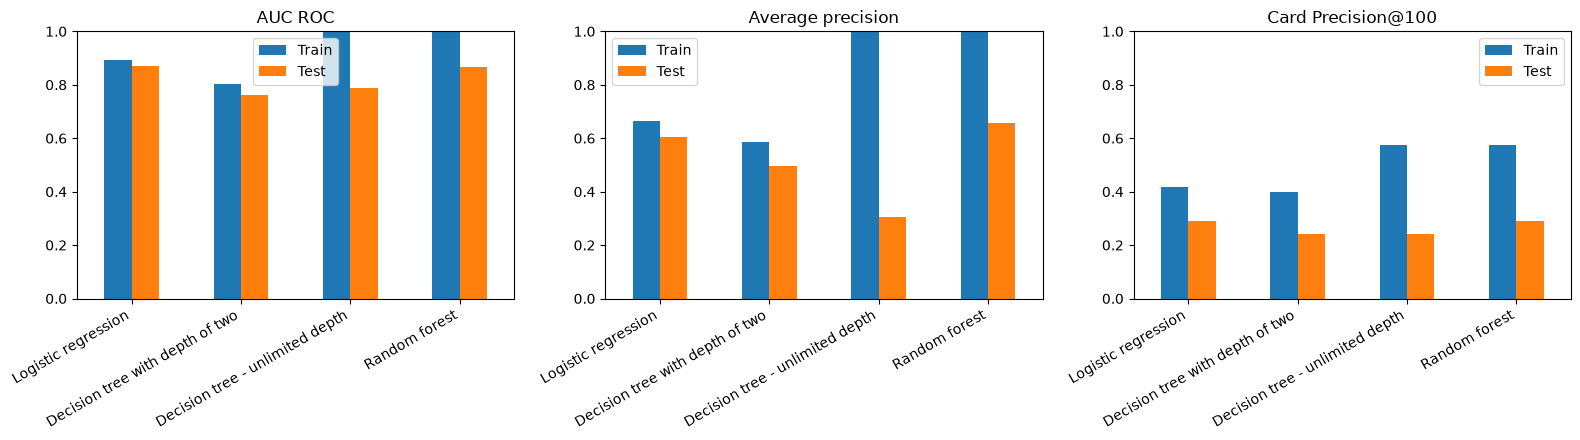

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric in zip(axes, df_performances_test.columns):
    pd.DataFrame({"Train": df_performances_train[metric], "Test": df_performances_test[metric]}).plot.bar(ax=ax, rot=30)
    ax.set_title(metric)
    ax.set_ylim(0, 1)
    ax.set_xticklabels(ax.get_xticklabels(), ha="right")
fig.tight_layout()

The model that overfits most is the unlimited-depth decision tree: near-perfect on the training set, much weaker on the test set. The ensemble models (random forest, and XGBoost if available) give the best test performance, which matches the handbook's results.

## 9. Online serving: scoring incoming transactions

Natural entity keys pay off at serving time. When a new transaction arrives, the model needs the same 15 inputs it was trained on:

| Model input | Where it comes from at serving time |
|---|---|
| `CUSTOMER_ID_*` (6 features) | **online store**, looked up by `CUSTOMER_ID` |
| `TERMINAL_ID_*` (6 features) | **online store**, looked up by `TERMINAL_ID` |
| `TX_DURING_WEEKEND`, `TX_DURING_NIGHT` | **on-demand feature view**, computed by Feast from the request's `event_timestamp` |
| `TX_AMOUNT` | the **request** itself (the transaction has never been stored, so there is nothing to look up) |

The online store is configured in `feature_store.yaml` (`online_store: type: sqlite`, file `data/online_store.db`). `feast apply` created one table per feature view. SQLite is fine for a local demo. In production you would typically switch to Redis, PostgreSQL, DynamoDB, Bigtable, etc., which only changes `feature_store.yaml`.

This section walks through four steps:

1. **Materialize**: a batch job loads the latest customer and terminal features from the offline store into the online store.
2. **Score** a few incoming transactions with the features currently in the online store.
3. **Push** fresh features for each incoming transaction to the online store, and score again.
4. **Compare** the scores and the feature values with what the model saw in training.

We pretend "now" is **2018-09-15 00:00**: the offline store is used up to that moment, and transactions from 2018-09-15 play the role of incoming requests.

### 9.1 Materialize the offline features into the online store

`store.materialize(start, end)` reads the feature rows with an event timestamp in `[start, end)` from the offline store and writes the **latest row per entity** to the online store. The online store keeps a single row per entity: no history.

`start` only needs to reach back as far as the views' TTL (30 days for customers, 37 days for terminals), since older rows would be considered expired anyway. In production this runs on a schedule, typically with `feast materialize-incremental <end>`, which continues from where the previous run stopped.

`transaction_features` is not materialized: its key is the transaction ID, and a new transaction is never in the store.

In [30]:
SERVING_CUTOFF = datetime.datetime(2018, 9, 15)

store.materialize(
    start_date=SERVING_CUTOFF - datetime.timedelta(days=37),
    end_date=SERVING_CUTOFF,
    feature_views=["customer_spending_features", "terminal_risk_features"],
)

Materializing 2 feature views from 2018-08-09 00:00:00+00:00 to 2018-09-15 00:00:00+00:00 into the sqlite online store.

customer_spending_features:
terminal_risk_features:


/Users/mesfinmulugeta/.local/share/virtualenvs/fraud-detection-using-feast-Ti0pUPAC/lib/python3.12/site-packages/ibis/backends/duckdb/__init__.py:332: DeprecationWarning: fetch_arrow_table() is deprecated, use to_arrow_table() instead.
  meta = result.fetch_arrow_table()


/Users/mesfinmulugeta/.local/share/virtualenvs/fraud-detection-using-feast-Ti0pUPAC/lib/python3.12/site-packages/ibis/backends/duckdb/__init__.py:332: DeprecationWarning: fetch_arrow_table() is deprecated, use to_arrow_table() instead.
  meta = result.fetch_arrow_table()


### 9.2 Incoming transactions

As incoming requests we take the first four transactions of 2018-09-15 and its first two frauds. A request only carries what the payment system knows at that moment: the transaction ID, timestamp, customer, terminal and amount. The label `TX_FRAUD` is kept aside to check the scores.

In [31]:
REQUEST_COLUMNS = ["TRANSACTION_ID", "TX_DATETIME", "CUSTOMER_ID", "TERMINAL_ID", "TX_AMOUNT"]

serving_day_df = transactions_df[
    (transactions_df.TX_DATETIME >= SERVING_CUTOFF)
    & (transactions_df.TX_DATETIME < SERVING_CUTOFF + datetime.timedelta(days=1))
]
incoming_df = pd.concat([serving_day_df.head(4), serving_day_df[serving_day_df.TX_FRAUD == 1].head(2)]).sort_values("TX_DATETIME")

incoming_requests = incoming_df[REQUEST_COLUMNS].reset_index(drop=True)
incoming_labels = incoming_df.TX_FRAUD.reset_index(drop=True)
incoming_requests.assign(TX_FRAUD=incoming_labels)

,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_AMOUNT,TX_FRAUD
0,1600653,2018-09-15 00:00:44,65,4899,7.67,0
1,1600654,2018-09-15 00:00:55,4168,6190,55.11,0
2,1600655,2018-09-15 00:01:09,3386,9949,138.34,0
3,1600656,2018-09-15 00:01:22,4738,5093,9.02,0
4,1600709,2018-09-15 00:38:43,3439,1560,121.35,1
5,1600737,2018-09-15 00:55:35,2057,4164,11.68,1


### 9.3 Score the incoming transactions

The scoring function does what an online inference service would do for each request:

1. Call `store.get_online_features` with the request's entity keys (`CUSTOMER_ID`, `TERMINAL_ID`) and its `event_timestamp` (request data for the on-demand feature view).
2. Add `TX_AMOUNT` from the request.
3. Standardise the inputs with the scaler fitted on the training set, and call the model.

The features requested are taken from the **feature service** `fraud_model_v1`, the same one used to build the training set. That keeps training and serving inputs in sync. Only `transaction_features` is left out, because `TX_AMOUNT` comes from the request.

We use the random forest trained in section 8. The training code scales the data internally without keeping the scaler, so we fit the same `StandardScaler` on the training set again.

In [32]:
fraud_model = fitted_models_and_predictions_dictionary["Random forest"]["classifier"]
scaler = sklearn.preprocessing.StandardScaler().fit(train_df[input_features])

# Same features as in training, except TX_AMOUNT, which comes with the request
ONLINE_FEATURES = [
    f"{projection.name}:{feature.name}"
    for projection in store.get_feature_service("fraud_model_v1").feature_view_projections
    if projection.name != "transaction_features"
    for feature in projection.features
]


def get_online_model_inputs(requests):
    # Look up the stored features and compute the on-demand ones for a batch of requests
    entity_rows = [
        {
            "CUSTOMER_ID": int(request.CUSTOMER_ID),
            "TERMINAL_ID": int(request.TERMINAL_ID),
            "event_timestamp": request.TX_DATETIME.to_pydatetime(),
        }
        for request in requests.itertuples()
    ]
    model_inputs = store.get_online_features(features=ONLINE_FEATURES, entity_rows=entity_rows).to_df()
    model_inputs.insert(0, "TRANSACTION_ID", requests.TRANSACTION_ID.values)
    model_inputs["TX_AMOUNT"] = requests.TX_AMOUNT.values
    return model_inputs


def score(model_inputs):
    # Fraud probability for each row of model inputs
    scaled_inputs = pd.DataFrame(scaler.transform(model_inputs[input_features]), columns=input_features)
    return fraud_model.predict_proba(scaled_inputs)[:, 1]


materialized_inputs = get_online_model_inputs(incoming_requests)
materialized_inputs["fraud_probability"] = score(materialized_inputs)
materialized_inputs.assign(TX_FRAUD=incoming_labels)

,TRANSACTION_ID,CUSTOMER_ID,TERMINAL_ID,CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW,CUSTOMER_ID_NB_TX_1DAY_WINDOW,CUSTOMER_ID_NB_TX_30DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW,CUSTOMER_ID_NB_TX_7DAY_WINDOW,TERMINAL_ID_NB_TX_1DAY_WINDOW,TERMINAL_ID_RISK_1DAY_WINDOW,TERMINAL_ID_NB_TX_7DAY_WINDOW,TERMINAL_ID_RISK_30DAY_WINDOW,TERMINAL_ID_NB_TX_30DAY_WINDOW,TERMINAL_ID_RISK_7DAY_WINDOW,TX_DURING_WEEKEND,TX_DURING_NIGHT,TX_AMOUNT,fraud_probability,TX_FRAUD
0,1600653,65,4899,6.802973,4.0,111.0,7.144500,8.0800,20.0,0.0,0.0,3.0,0.000000,27.0,0.0,1,1,7.67,0.00,0
1,1600654,4168,6190,39.573542,3.0,96.0,44.545652,51.3700,23.0,1.0,0.0,9.0,0.000000,29.0,0.0,1,1,55.11,0.00,0
2,1600655,3386,9949,87.314643,2.0,28.0,114.818571,99.8800,7.0,3.0,0.0,14.0,0.000000,40.0,0.0,1,1,138.34,0.00,0
3,1600656,4738,5093,98.617500,4.0,68.0,116.572222,104.3925,18.0,1.0,0.0,5.0,0.000000,25.0,0.0,1,1,9.02,0.00,0
4,1600709,3439,1560,71.740745,5.0,94.0,75.996522,52.7000,23.0,0.0,0.0,2.0,0.000000,28.0,0.0,1,1,121.35,0.00,1
5,1600737,2057,4164,21.556667,2.0,54.0,19.839412,22.1200,17.0,0.0,0.0,10.0,0.458333,24.0,1.0,1,1,11.68,0.86,1


**These features are stale.** Materialization stored, for each customer and terminal, the values computed at its **last transaction before the cutoff**. The model was trained on values computed **at the transaction being scored**: for example, `CUSTOMER_ID_NB_TX_1DAY_WINDOW` counts the customer's transactions in the day *ending at the current transaction*, including it.

We can check this, since these transactions are in our data. `transactions_df` holds the feature values computed with the training definitions (the same values the offline store has):

In [33]:
CUSTOMER_FEATURES = [f for f in input_features if f.startswith("CUSTOMER_ID_")]
TERMINAL_FEATURES = [f for f in input_features if f.startswith("TERMINAL_ID_")]

# Feature values for these transactions, computed with the training definitions (section 2)
expected_inputs = transactions_df.set_index("TRANSACTION_ID").loc[incoming_requests.TRANSACTION_ID, CUSTOMER_FEATURES + TERMINAL_FEATURES]
expected_inputs = expected_inputs.reset_index()


def compare_with_training_values(model_inputs):
    # Side-by-side view of a few online values and the values the training definitions give
    matches = np.isclose(model_inputs[CUSTOMER_FEATURES + TERMINAL_FEATURES].astype(float), expected_inputs[CUSTOMER_FEATURES + TERMINAL_FEATURES])
    return pd.DataFrame(
        {
            "TRANSACTION_ID": model_inputs.TRANSACTION_ID,
            "CUSTOMER_NB_TX_1DAY (online)": model_inputs.CUSTOMER_ID_NB_TX_1DAY_WINDOW,
            "CUSTOMER_NB_TX_1DAY (training definition)": expected_inputs.CUSTOMER_ID_NB_TX_1DAY_WINDOW,
            "TERMINAL_NB_TX_7DAY (online)": model_inputs.TERMINAL_ID_NB_TX_7DAY_WINDOW,
            "TERMINAL_NB_TX_7DAY (training definition)": expected_inputs.TERMINAL_ID_NB_TX_7DAY_WINDOW,
            "all 12 features match": matches.all(axis=1),
        }
    )


compare_with_training_values(materialized_inputs)

,TRANSACTION_ID,CUSTOMER_NB_TX_1DAY (online),CUSTOMER_NB_TX_1DAY (training definition),TERMINAL_NB_TX_7DAY (online),TERMINAL_NB_TX_7DAY (training definition),all 12 features match
0,1600653,4.0,5.0,3.0,3.0,False
1,1600654,3.0,4.0,9.0,10.0,False
2,1600655,2.0,2.0,14.0,14.0,False
3,1600656,4.0,1.0,5.0,8.0,False
4,1600709,5.0,6.0,2.0,1.0,False
5,1600737,2.0,1.0,10.0,7.0,False


### 9.4 Push fresh features to the online store

To serve the values the model was trained on, the customer and terminal features must be **recomputed when a transaction arrives** and written to the online store before the model is called. Feast supports this with a **push source**:

* In `features.py`, `customer_spending_features` and `terminal_risk_features` read from a `PushSource` (`customer_spending_push_source`, `terminal_risk_push_source`) instead of the `FileSource` directly. Each push source wraps the `FileSource` as its `batch_source`, so training (`get_historical_features`) and materialization still read the Parquet files exactly as before.
* `store.push(push_source_name, df, to=PushMode.ONLINE)` writes a dataframe of fresh values to every feature view that uses that push source. The dataframe needs the entity key, the timestamp column (`TX_DATETIME`) and the features. `PushMode.OFFLINE` / `ONLINE_AND_OFFLINE` would also append the rows to the offline store. We don't need that here, since the batch pipeline already writes them.

In production a stream processor (e.g. Flink, Spark Structured Streaming or a Kafka consumer) would keep each customer's and terminal's recent transactions, recompute the windows and call `store.push`, or send them to the `/push` endpoint of a Feast feature server (`feast serve`). The scoring service then reads them with `get_online_features`, or the feature server's `/get-online-features` endpoint.

Here we simulate that in a loop, one transaction at a time, with the handbook functions from section 2:

1. Take the customer's transactions from the last 30 days (the terminal's from the last 37 days) plus the incoming one.
2. Recompute the windowed features and keep the row for the incoming transaction.
3. Push it to the online store.
4. Read the online features and score the transaction.

The incoming transaction's own label isn't known yet. The terminal risk only counts frauds older than the 7-day delay, so we can set it to 0: it adds the same amount to both rolling sums in `get_count_risk_rolling_window`, and they cancel out.

In [34]:
from feast.data_source import PushMode

# What the payment system has recorded before the incoming transactions (raw columns, labels included)
history_df = transactions_df[REQUEST_COLUMNS + ["TX_FRAUD"]]


def compute_fresh_features(request, history_df):
    # Customer and terminal features for an incoming transaction, computed as in training (section 2)
    tx_datetime = request.TX_DATETIME
    history_df = history_df[history_df.TX_DATETIME < tx_datetime]
    # The label of the incoming transaction is unknown; it does not affect the delayed terminal windows
    new_transaction = pd.DataFrame([request._asdict()]).assign(TX_FRAUD=0)

    customer_transactions = pd.concat([
        history_df[(history_df.CUSTOMER_ID == request.CUSTOMER_ID) & (history_df.TX_DATETIME > tx_datetime - datetime.timedelta(days=30))],
        new_transaction,
    ])
    customer_update = get_customer_spending_behaviour_features(customer_transactions)
    customer_update = customer_update.loc[[request.TRANSACTION_ID], ["CUSTOMER_ID", "TX_DATETIME"] + CUSTOMER_FEATURES]

    terminal_transactions = pd.concat([
        history_df[(history_df.TERMINAL_ID == request.TERMINAL_ID) & (history_df.TX_DATETIME > tx_datetime - datetime.timedelta(days=37))],
        new_transaction,
    ])
    terminal_update = get_count_risk_rolling_window(terminal_transactions)
    terminal_update = terminal_update.loc[[request.TRANSACTION_ID], ["TERMINAL_ID", "TX_DATETIME"] + TERMINAL_FEATURES]

    return customer_update.reset_index(drop=True), terminal_update.reset_index(drop=True)


pushed_inputs = []
for request in incoming_requests.itertuples(index=False):
    customer_update, terminal_update = compute_fresh_features(request, history_df)

    store.push("customer_spending_push_source", customer_update, to=PushMode.ONLINE)
    store.push("terminal_risk_push_source", terminal_update, to=PushMode.ONLINE)

    pushed_inputs.append(get_online_model_inputs(pd.DataFrame([request._asdict()])))

pushed_inputs = pd.concat(pushed_inputs, ignore_index=True)
pushed_inputs["fraud_probability"] = score(pushed_inputs)
pushed_inputs.assign(TX_FRAUD=incoming_labels)

,TRANSACTION_ID,CUSTOMER_ID,TERMINAL_ID,CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW,CUSTOMER_ID_NB_TX_1DAY_WINDOW,CUSTOMER_ID_NB_TX_30DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW,CUSTOMER_ID_NB_TX_7DAY_WINDOW,TERMINAL_ID_NB_TX_1DAY_WINDOW,TERMINAL_ID_RISK_1DAY_WINDOW,TERMINAL_ID_NB_TX_7DAY_WINDOW,TERMINAL_ID_RISK_30DAY_WINDOW,TERMINAL_ID_NB_TX_30DAY_WINDOW,TERMINAL_ID_RISK_7DAY_WINDOW,TX_DURING_WEEKEND,TX_DURING_NIGHT,TX_AMOUNT,fraud_probability,TX_FRAUD
0,1600653,65,4899,6.841802,5.0,111.0,7.169524,7.998000,21.0,0.0,0.0,3.0,0.000000,27.0,0.0,1,1,7.67,0.00,0
1,1600654,4168,6190,39.733711,4.0,97.0,44.985833,52.305000,24.0,2.0,0.0,10.0,0.000000,28.0,0.0,1,1,55.11,0.01,0
2,1600655,3386,9949,90.401429,2.0,28.0,100.021667,120.775000,6.0,2.0,0.0,14.0,0.000000,39.0,0.0,1,1,138.34,0.00,0
3,1600656,4738,5093,99.268571,1.0,63.0,115.845000,9.020000,14.0,1.0,0.0,8.0,0.000000,28.0,0.0,1,1,9.02,0.00,0
4,1600709,3439,1560,72.262947,6.0,95.0,77.886250,64.141667,24.0,0.0,0.0,1.0,0.000000,28.0,0.0,1,1,121.35,0.00,1
5,1600737,2057,4164,21.282037,1.0,54.0,18.240000,11.680000,17.0,0.0,0.0,7.0,0.478261,23.0,1.0,1,1,11.68,0.92,1


After the push, the online values are the ones the training definitions give:

In [35]:
compare_with_training_values(pushed_inputs)

,TRANSACTION_ID,CUSTOMER_NB_TX_1DAY (online),CUSTOMER_NB_TX_1DAY (training definition),TERMINAL_NB_TX_7DAY (online),TERMINAL_NB_TX_7DAY (training definition),all 12 features match
0,1600653,5.0,5.0,3.0,3.0,True
1,1600654,4.0,4.0,10.0,10.0,True
2,1600655,2.0,2.0,14.0,14.0,True
3,1600656,1.0,1.0,8.0,8.0,True
4,1600709,6.0,6.0,1.0,1.0,True
5,1600737,1.0,1.0,7.0,7.0,True


### 9.5 Compare the scores

In [36]:
pd.DataFrame(
    {
        "TRANSACTION_ID": incoming_requests.TRANSACTION_ID,
        "TX_FRAUD": incoming_labels,
        "fraud probability (materialized features)": materialized_inputs.fraud_probability,
        "fraud probability (pushed features)": pushed_inputs.fraud_probability,
    }
)

,TRANSACTION_ID,TX_FRAUD,fraud probability (materialized features),fraud probability (pushed features)
0,1600653,0,0.00,0.00
1,1600654,0,0.00,0.01
2,1600655,0,0.00,0.00
3,1600656,0,0.00,0.00
4,1600709,1,0.00,0.00
5,1600737,1,0.86,0.92


With only six transactions the scores may differ little, but the inputs show the point: only the pushed features match what the model was trained on. With stale features the model scores a transaction with a picture of the customer and terminal that can be hours or days old. A burst of fraudulent transactions on a card, for instance, would not show up in `CUSTOMER_ID_NB_TX_1DAY_WINDOW` until the next materialization.

**Ways to keep the online features fresh:**

| Approach | Freshness | Effort |
|---|---|---|
| Scheduled `materialize-incremental` (hourly, daily) | stale by up to one interval, and anchored at each entity's last transaction | lowest: a cron job |
| Push on every transaction (this section) | matches training | needs a stream processor that keeps each entity's recent transactions |
| Mixed: push the customer features, materialize the terminal features daily | customer windows fresh; terminal risk lags a little | the terminal risk depends on labels from more than 7 days ago, so it changes slowly |

## Summary

* The windowed customer and terminal features were computed with the handbook's pandas code and stored as daily-partitioned Parquet files. The weekend/night features are an **on-demand feature view** that Feast computes at retrieval time.
* Feature definitions were registered with `feast apply` / `store.apply` and inspected from the CLI and the SDK.
* `get_historical_features` built a point-in-time correct training set from an entity dataframe, quickly with DuckDB and slowly with Dask.
* The same definitions serve features online by customer and terminal. `materialize` loads them in batch; **push sources** keep them fresh as transactions arrive, so incoming transactions are scored with the same inputs the model was trained on. That is the main advantage of this design over the single transaction-keyed view in the sibling notebook.